# Test de índices bursátiles — FMPAPI

Notebook preparado para guardarse en **`tests/test_indices_fmp.ipynb`**. Comprueba la integración de `FMPAPI.get_index()` con la clase `Index`, descarga histórica y, opcionalmente, los constituyentes del S&P 500.

**Requisitos:** `pandas`, `requests`, `python-dotenv` (opcional), `matplotlib` (opcional), conexión a Internet y `FMP_API_KEY` en el archivo `.env` de la raíz. **No se ejecutan llamadas reales al crear este notebook.**

**Importante:** La disponibilidad de los endpoints, los símbolos de índices y los componentes depende de la cobertura y suscripción de FMP. Un error 402/403 no implica que tu código esté mal.

## 1. Detectar la raíz del proyecto y cargar `.env`

In [1]:
import os
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
project_root = next(
    (p for p in (cwd, *cwd.parents) if (p / "src" / "financial_toolkit" / "fmp_api.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "No se encontró src/financial_toolkit/fmp_api.py. Ejecuta el notebook desde tests/ o la raíz del repositorio."
    )
models_dir = project_root / "src" / "financial_toolkit"
if str(models_dir.parent) not in sys.path:
    sys.path.insert(0, str(models_dir.parent))

try:
    from dotenv import load_dotenv
    load_dotenv(project_root / ".env")
except ImportError:
    print("python-dotenv no instalado; se usarán las variables de entorno ya cargadas.")

print("Raíz:", project_root)
print("Modelos:", models_dir)

Raíz: /Users/hugoballesteromartin/Documents/HBM PRODUCTIONS/BME/Entregas/Entrega Bloque 1/Financial-Toolkit
Modelos: /Users/hugoballesteromartin/Documents/HBM PRODUCTIONS/BME/Entregas/Entrega Bloque 1/Financial-Toolkit/src/models


## 2. Importar modelos e inicializar FMP

In [2]:
import pandas as pd
from financial_toolkit.fmp_api import FMPAPI
from financial_toolkit.priceseries import PriceSeries
from financial_toolkit.index import Index

api_key = os.getenv("FMP_API_KEY") or os.getenv("FMP_APIKEY")
if not api_key:
    raise EnvironmentError(
        "Falta FMP_API_KEY. Añade FMP_API_KEY=tu_clave al .env de la raíz del proyecto."
    )

api = FMPAPI(api_key=api_key)
assert callable(getattr(api, "get_index", None)), (
    "FMPAPI no tiene get_index(). Añade primero el método a src/financial_toolkit/fmp_api.py."
)
print("FMPAPI inicializada; método get_index disponible.")

FMPAPI inicializada; método get_index disponible.


## 3. Consultar índices

**Ajusta `INDEX_SYMBOLS` a los símbolos admitidos por tu plan de FMP.** Los tickers `^GSPC`, `^NDX` y `^DJI` son habituales en Yahoo Finance, pero **no se garantiza que FMP los acepte**. Por eso las pruebas registran los errores sin detener todo el notebook.

In [3]:
# Modifica estos símbolos si tu cuenta de FMP utiliza otra nomenclatura.
INDEX_SYMBOLS = {
    "S&P 500": "^GSPC",
    "NASDAQ-100": "^NDX",
    "Dow Jones": "^DJI",
}
PERIOD = "1y"  # reduce la cantidad de datos para la prueba

results = {}
errors = {}
for name, symbol in INDEX_SYMBOLS.items():
    print(f"\nConsultando {name} ({symbol})...")
    try:
        obj = api.get_index(symbol=symbol, period=PERIOD)
        results[name] = obj
        print(f"  OK: {obj.name} | {len(obj.price.close)} observaciones")
    except Exception as exc:
        errors[name] = f"{type(exc).__name__}: {exc}"
        print("  No disponible:", errors[name])

print(f"\nDescargas correctas: {len(results)} / {len(INDEX_SYMBOLS)}")
if not results:
    print("Ningún índice descargado. Comprueba la clave, el plan, el endpoint y los símbolos FMP.")


Consultando S&P 500 (^GSPC)...
  OK: S&P 500 | 255 observaciones

Consultando NASDAQ-100 (^NDX)...
  No disponible: ValueError: Historical prices for ^NDX require a paid FMP subscription

Consultando Dow Jones (^DJI)...
  OK: Dow Jones Industrial Average | 255 observaciones

Descargas correctas: 2 / 3


## 4. Validaciones de `Index` y `PriceSeries`

In [4]:
def validate_index(index_obj, requested_symbol):
    assert isinstance(index_obj, Index), "El resultado debe ser una instancia de Index"
    assert index_obj.symbol == requested_symbol, "El símbolo no coincide"
    assert isinstance(index_obj.price, PriceSeries), "price debe ser PriceSeries"
    p = index_obj.price
    assert isinstance(p.date, pd.DatetimeIndex), "date debe ser DatetimeIndex"
    assert len(p.date) > 0, "La serie está vacía"
    assert p.date.is_monotonic_increasing, "Las fechas no están ordenadas"
    for field in ("open", "high", "low", "close"):
        series = getattr(p, field)
        assert isinstance(series, pd.Series), f"{field} debe ser una Series"
        assert len(series) == len(p.date), f"Longitud incorrecta en {field}"
        assert series.notna().any(), f"{field} no tiene valores válidos"
    if p.volume is not None:
        assert isinstance(p.volume, pd.Series), "volume debe ser Series o None"
        assert len(p.volume) == len(p.date), "Longitud incorrecta en volume"
    assert index_obj.constituents is None or isinstance(index_obj.constituents, pd.DataFrame)
    assert index_obj.sector_weights is None or isinstance(index_obj.sector_weights, dict)
    return True

for name, obj in results.items():
    validate_index(obj, INDEX_SYMBOLS[name])
    print(f"✓ {name}: validación superada")

if not results:
    print("Validaciones omitidas: no hay datos descargados.")

✓ S&P 500: validación superada
✓ Dow Jones: validación superada


## 5. Visualizar precios y metadatos

In [5]:
for name, obj in results.items():
    print(f"\n{name}:")
    print("  Nombre:", obj.name)
    print("  Símbolo:", obj.symbol)
    print("  País:", obj.country)
    print("  Divisa:", obj.currency)
    print("  Mercado:", obj.exchange)
    print("  Últimos cierres:")
    display(obj.price.close.tail().to_frame(name="close"))


S&P 500:
  Nombre: S&P 500
  Símbolo: ^GSPC
  País: United States
  Divisa: USD
  Mercado: None
  Últimos cierres:


,close
date,
2026-10-28,7743.98
2026-10-29,7720.39
2026-10-30,7580.07
2026-11-02,7541.40
2026-11-03,7587.05



Dow Jones:
  Nombre: Dow Jones Industrial Average
  Símbolo: ^DJI
  País: United States
  Divisa: USD
  Mercado: None
  Últimos cierres:


,close
date,
2026-10-28,52475.10
2026-10-29,52342.56
2026-10-30,51770.31
2026-11-02,51983.98
2026-11-03,51867.04


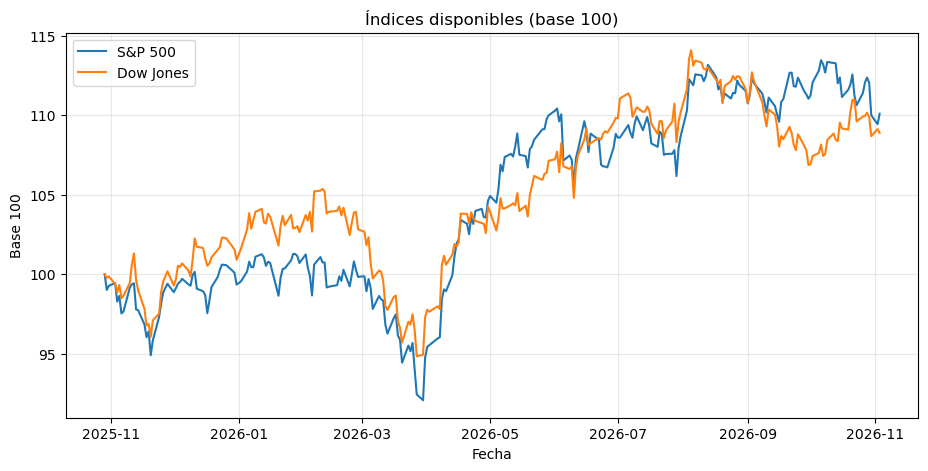

In [6]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("Instala matplotlib si quieres visualizar los gráficos.")
else:
    if results:
        plt.figure(figsize=(11, 5))
        for name, obj in results.items():
            close = obj.price.close.dropna()
            if not close.empty and close.iloc[0] != 0:
                normalized = close / close.iloc[0] * 100
                plt.plot(normalized.index, normalized.values, label=name)
        plt.title("Índices disponibles (base 100)")
        plt.xlabel("Fecha")
        plt.ylabel("Base 100")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()
    else:
        print("Gráfico omitido: no hay series disponibles.")

## 6. Resumen de las pruebas

In [8]:
summary = pd.DataFrame([
    {
        "índice": name,
        "símbolo": symbol,
        "estado": "OK" if name in results else "ERROR / SIN ACCESO",
        "observaciones": len(results[name].price.close) if name in results else 0,
        "detalle": errors.get(name, ""),
    }
    for name, symbol in INDEX_SYMBOLS.items()
])
display(summary)

if not results:
    print("Consejo: comprueba la documentación de FMP para los símbolos y endpoints de índices de tu plan.")
else:
    print("Validación de los índices descargados completada.")

,índice,símbolo,estado,observaciones,detalle
0,S&P 500,^GSPC,OK,255,
1,NASDAQ-100,^NDX,ERROR / SIN ACCESO,0,ValueError: Historical prices for ^NDX require...
2,Dow Jones,^DJI,OK,255,


Validación de los índices descargados completada.


### Nota sobre errores habituales

- **402 / 403**: endpoint no incluido en la suscripción o acceso restringido.
- **Respuesta vacía**: símbolo no reconocido, falta de cobertura o rango de fechas sin datos.
- **`AttributeError: get_index`**: el método todavía no se ha incorporado a `fmp_api.py`.
- **`ModuleNotFoundError`**: revisa los nombres de archivo de `index.py`, `priceseries.py` y `fmp_api.py`.
- **Pesos**: el endpoint `sp500-constituent` no debe tratarse como fuente de ponderaciones salvo que las devuelva expresamente.